In [20]:

import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------
np.random.seed(42)

OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N = 5000

regions = [
    "Mumbai", "Pune", "Nagpur",
    "Nashik", "Thane", "Aurangabad"
]

services = [
    "ILL", "MPLS", "Ethernet",
    "Fibre", "SIP Trunk"
]

# --------------------------------------------------
# 2. GENERATE SYNTHETIC DATA
# --------------------------------------------------
df = pd.DataFrame({
    "record_id": range(1, N + 1),
    "region": np.random.choice(regions, N),
    "service_type": np.random.choice(services, N),
    "monthly_revenue": np.random.randint(10000, 250000, N),
    "activation_delay_days": np.random.poisson(3, N),
    "capex_amount": np.random.randint(5000, 100000, N),
    "month": np.random.choice(
        pd.date_range(
            "2026-01-01",
            periods=10,
            freq="MS"
        ).strftime("%Y-%m"),
        N
    )
})

# Generate billing and collection amounts
df["billed_amount"] = (
    df["monthly_revenue"]
    * np.random.uniform(0.90, 1.05, N)
).round(2)

df["collection_amount"] = (
    df["billed_amount"]
    * np.random.uniform(0.70, 0.98, N)
).round(2)

# --------------------------------------------------
# 3. INSERT CONTROLLED ANOMALIES
# --------------------------------------------------
anomaly_indices = np.random.choice(
    df.index, 100, replace=False
)

# 35 deliberately low-billing records
billing_idx = anomaly_indices[:35]

df.loc[billing_idx, "billed_amount"] = (
    df.loc[billing_idx, "monthly_revenue"] * 0.35
).round(2)

# 35 deliberately delayed activations
activation_idx = anomaly_indices[35:70]

df.loc[activation_idx, "activation_delay_days"] += 20

# 30 deliberately zero-collection records
collection_idx = anomaly_indices[70:]

df.loc[collection_idx, "collection_amount"] = 0.0

# --------------------------------------------------
# 4. ENFORCE FINANCIAL DATA CONSISTENCY
# --------------------------------------------------
# Billed amount cannot exceed expected revenue in this
# simplified synthetic dataset.
df["billed_amount"] = np.minimum(
    df["billed_amount"],
    df["monthly_revenue"]
).round(2)

# Collections cannot exceed billed amount.
# Zero-collection anomalies remain zero.
df["collection_amount"] = np.minimum(
    df["collection_amount"],
    df["billed_amount"]
).round(2)

# Ensure monetary columns use consistent numeric types.
money_columns = [
    "monthly_revenue",
    "billed_amount",
    "collection_amount",
    "capex_amount"
]

df[money_columns] = df[money_columns].astype("float64")

# --------------------------------------------------
# 5. CALCULATE GAPS
# --------------------------------------------------
df["billing_gap"] = (
    df["monthly_revenue"] - df["billed_amount"]
).round(2)

df["collection_gap"] = (
    df["billed_amount"] - df["collection_amount"]
).round(2)

# --------------------------------------------------
# 6. VALIDATE DATA
# --------------------------------------------------
assert len(df) == N, "Unexpected record count"
assert df["record_id"].is_unique, "Duplicate record IDs found"
assert not df.isnull().any().any(), "Missing values found"

assert (
    df["billed_amount"] <= df["monthly_revenue"]
).all(), "Billing consistency check failed"

assert (
    df["collection_amount"] <= df["billed_amount"]
).all(), "Collection consistency check failed"

assert (df["collection_amount"] >= 0).all()
assert (df["billed_amount"] >= 0).all()

# --------------------------------------------------
# 7. EXPORT RAW DATASET
# --------------------------------------------------
df.to_csv(
    OUTPUT_DIR / "telecom_revenue_data.csv",
    index=False
)

print("DATASET GENERATED SUCCESSFULLY")
print("-" * 40)
print("Total records:", len(df))
print("Unique record IDs:", df["record_id"].nunique())
print("Missing values:", int(df.isnull().sum().sum()))
print(
    "Low-billing records:",
    int(
        (
            df["billed_amount"]
            < df["monthly_revenue"] * 0.50
        ).sum()
    )
)
print(
    "Delayed activations:",
    int((df["activation_delay_days"] > 10).sum())
)
print(
    "Zero-collection records:",
    int((df["collection_amount"] == 0).sum())
)
print(
    "Billed amount exceeds revenue:",
    int(
        (
            df["billed_amount"] > df["monthly_revenue"]
        ).sum()
    )
)
print(
    "Collections exceed billed amount:",
    int(
        (
            df["collection_amount"] > df["billed_amount"]
        ).sum()
    )
)

display(df.head())


DATASET GENERATED SUCCESSFULLY
----------------------------------------
Total records: 5000
Unique record IDs: 5000
Missing values: 0
Low-billing records: 35
Delayed activations: 36
Zero-collection records: 30
Billed amount exceeds revenue: 0
Collections exceed billed amount: 0


,record_id,region,service_type,monthly_revenue,activation_delay_days,capex_amount,month,billed_amount,collection_amount,billing_gap,collection_gap
0,1,Nashik,Fibre,136244.0,4,21771.0,2026-03,125064.69,114352.61,11179.31,10712.08
1,2,Thane,ILL,42813.0,7,66182.0,2026-02,40805.45,35833.97,2007.55,4971.48
2,3,Nagpur,Fibre,76729.0,4,81759.0,2026-10,73078.55,62750.08,3650.45,10328.47
3,4,Thane,Fibre,201758.0,0,37714.0,2026-09,186152.13,146889.33,15605.87,39262.80
4,5,Thane,Fibre,14512.0,2,35429.0,2026-09,14512.00,10622.15,0.00,3889.85


In [21]:

# Step 2: Data quality and anomaly validation

print("DATA QUALITY CHECK")
print("-" * 35)

print("Total records:", len(df))
print("Duplicate record IDs:", df["record_id"].duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

print("\nANOMALY CHECK")
print("-" * 35)

print("Low billing records:",
      (df["billed_amount"] < df["monthly_revenue"] * 0.5).sum())

print("Delayed activations (over 10 days):",
      (df["activation_delay_days"] > 10).sum())

print("Zero collection records:",
      (df["collection_amount"] == 0).sum())

print("\nSUMMARY STATISTICS")
display(
    df[[
        "monthly_revenue",
        "billed_amount",
        "activation_delay_days",
        "collection_amount",
        "capex_amount"
    ]].describe().round(2)
)


DATA QUALITY CHECK
-----------------------------------
Total records: 5000
Duplicate record IDs: 0
Missing values: 0

ANOMALY CHECK
-----------------------------------
Low billing records: 35
Delayed activations (over 10 days): 36
Zero collection records: 30

SUMMARY STATISTICS


,monthly_revenue,billed_amount,activation_delay_days,collection_amount,capex_amount
count,5000.00,5000.00,5000.00,5000.00,5000.00
mean,128491.12,123668.80,3.16,104490.10,52390.10
std,69852.02,67840.09,2.40,59447.20,27669.44
min,10015.00,6031.20,0.00,0.00,5002.00
25%,66885.75,63829.96,2.00,52548.09,28809.25
50%,127785.50,122555.94,3.00,103063.16,52040.50
75%,190129.25,183243.60,4.00,152957.66,76621.25
max,249947.00,249947.00,28.00,247798.97,99968.00


In [22]:


# Step 3: Identify potential revenue and operations anomalies

# Billing is flagged when billed amount is below 50% of expected revenue
df["billing_anomaly"] = (
    df["billed_amount"] < df["monthly_revenue"] * 0.50
)

# Activation is flagged when delay exceeds 10 days
df["activation_anomaly"] = (
    df["activation_delay_days"] > 10
)

# Collection is flagged when no amount has been collected
# despite a positive billed amount
df["collection_anomaly"] = (
    (df["collection_amount"] == 0) &
    (df["billed_amount"] > 0)
)

# Flag a record if any rule is triggered
df["potential_anomaly"] = (
    df["billing_anomaly"] |
    df["activation_anomaly"] |
    df["collection_anomaly"]
)

print("ANOMALY DETECTION RESULTS")
print("-" * 35)
print("Billing flags:", int(df["billing_anomaly"].sum()))
print("Activation flags:", int(df["activation_anomaly"].sum()))
print("Collection flags:", int(df["collection_anomaly"].sum()))
print("Unique records flagged:", int(df["potential_anomaly"].sum()))
print(
    "Flagged record percentage:",
    round(df["potential_anomaly"].mean() * 100, 2), "%"
)

print("\nSample flagged records:")
display(
    df.loc[
        df["potential_anomaly"],
        [
            "record_id", "region", "service_type",
            "monthly_revenue", "billed_amount",
            "activation_delay_days", "collection_amount",
            "billing_anomaly", "activation_anomaly",
            "collection_anomaly"
        ]
    ].head(10)
)


ANOMALY DETECTION RESULTS
-----------------------------------
Billing flags: 35
Activation flags: 36
Collection flags: 30
Unique records flagged: 101
Flagged record percentage: 2.02 %

Sample flagged records:


,record_id,region,service_type,monthly_revenue,billed_amount,activation_delay_days,collection_amount,billing_anomaly,activation_anomaly,collection_anomaly
12,13,Aurangabad,Fibre,74591.0,68030.63,21,50490.76,False,True,False
14,15,Pune,Ethernet,215888.0,205306.64,2,0.00,False,False,True
19,20,Nashik,Ethernet,113627.0,39769.45,2,39769.45,True,False,False
50,51,Aurangabad,Fibre,37610.0,37610.00,5,0.00,False,False,True
105,106,Nashik,Fibre,232396.0,81338.60,0,81338.60,True,False,False
194,195,Mumbai,Ethernet,63171.0,22109.85,2,22109.85,True,False,False
292,293,Nashik,SIP Trunk,46943.0,46943.00,4,0.00,False,False,True
393,394,Thane,ILL,35825.0,12538.75,5,12538.75,True,False,False
453,454,Nashik,ILL,93583.0,32754.05,4,32754.05,True,False,False
598,599,Nagpur,MPLS,232345.0,81320.75,4,81320.75,True,False,False


In [23]:

# Step 4: Assign anomaly severity and priority

df["anomaly_score"] = (
    df["billing_anomaly"].astype(int) * 3
    + df["activation_anomaly"].astype(int) * 2
    + df["collection_anomaly"].astype(int) * 3
)

df["priority"] = np.select(
    [
        df["anomaly_score"] >= 5,
        df["anomaly_score"] >= 3,
        df["anomaly_score"] == 2
    ],
    [
        "High",
        "Medium",
        "Low"
    ],
    default="No Alert"
)

print("PRIORITY DISTRIBUTION")
display(
    df["priority"]
    .value_counts()
    .rename_axis("Priority")
    .reset_index(name="Records")
)

print("\nHIGH-PRIORITY RECORDS")
display(
    df.loc[
        df["priority"] == "High",
        [
            "record_id", "region", "service_type",
            "monthly_revenue", "billed_amount",
            "activation_delay_days", "collection_amount",
            "anomaly_score", "priority"
        ]
    ].head(10)
)


PRIORITY DISTRIBUTION


,Priority,Records
0,No Alert,4899
1,Medium,65
2,Low,36



HIGH-PRIORITY RECORDS


,record_id,region,service_type,monthly_revenue,billed_amount,activation_delay_days,collection_amount,anomaly_score,priority


In [24]:

# Step 5: Export analysis results

# Save complete dataset with anomaly flags
df.to_csv(OUTPUT_DIR / "telecom_revenue_analyzed.csv", index=False)

# Save only flagged records
flagged_df = df[df["potential_anomaly"]].copy()
flagged_df.to_csv(OUTPUT_DIR / "telecom_anomaly_alerts.csv", index=False)

# Save priority summary
priority_summary = (
    df.groupby("priority")
      .size()
      .reset_index(name="record_count")
)
priority_summary.to_csv(OUTPUT_DIR / "priority_summary.csv", index=False)

# Save regional performance summary
regional_summary = (
    df.groupby("region")
      .agg(
          total_revenue=("monthly_revenue", "sum"),
          total_billed=("billed_amount", "sum"),
          total_collections=("collection_amount", "sum"),
          flagged_records=("potential_anomaly", "sum")
      )
      .reset_index()
)
regional_summary.to_csv(OUTPUT_DIR / "regional_revenue_summary.csv", index=False)

print("Reports exported successfully!")
print("Analyzed records:", len(df))
print("Flagged records:", len(flagged_df))
print("\nFiles created:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)

display(priority_summary)


Reports exported successfully!
Analyzed records: 5000
Flagged records: 101

Files created:
- priority_summary.csv
- regional_revenue_summary.csv
- telecom_anomaly_alerts.csv
- telecom_revenue_analyzed.csv
- telecom_revenue_data.csv


,priority,record_count
0,Low,36
1,Medium,65
2,No Alert,4899


In [7]:

print("Regional summary:")
display(regional_summary)

print("\nCharts ready to generate.")


Regional summary:


,region,total_revenue,total_billed,total_collections,flagged_records
0,Aurangabad,103799237.0,1.044130e+08,98247860.0,192
1,Mumbai,114167948.0,1.138813e+08,104299331.0,210
2,Nagpur,103981663.0,1.035987e+08,99954916.0,193
3,Nashik,110666024.0,1.109005e+08,103994863.0,207
4,Pune,103509085.0,1.022104e+08,94326666.0,202
5,Thane,106331668.0,1.078218e+08,103840269.0,221



Charts ready to generate.


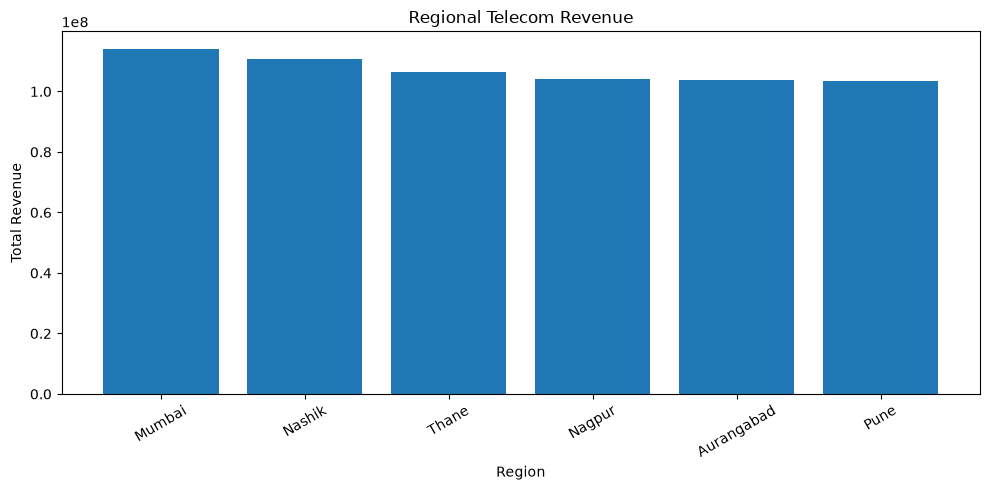

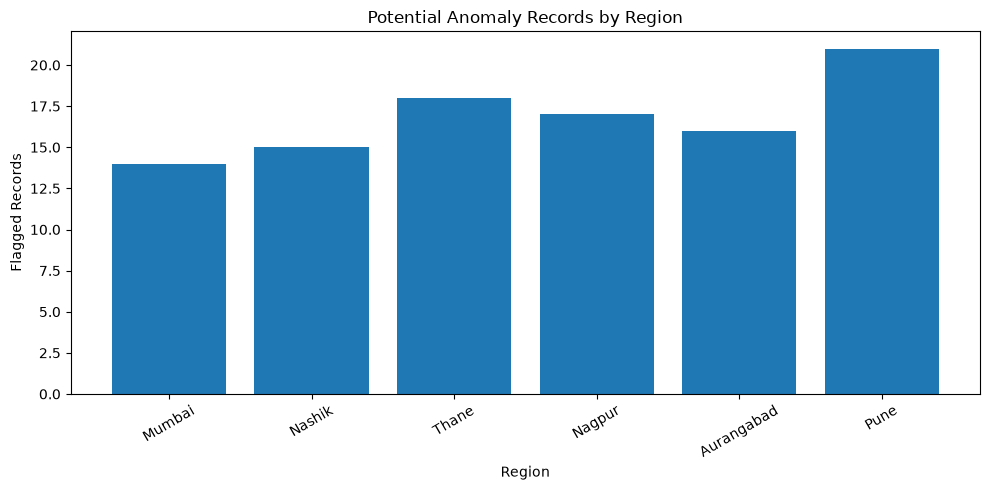

Both charts generated successfully.


In [25]:

import matplotlib.pyplot as plt

# Chart 1: Regional revenue comparison
regional_plot = regional_summary.sort_values(
    "total_revenue", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(regional_plot["region"], regional_plot["total_revenue"])
plt.title("Regional Telecom Revenue")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Chart 2: Potential anomalies by region
plt.figure(figsize=(10, 5))
plt.bar(regional_plot["region"], regional_plot["flagged_records"])
plt.title("Potential Anomaly Records by Region")
plt.xlabel("Region")
plt.ylabel("Flagged Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Both charts generated successfully.")


In [26]:

print("ANOMALY COUNTS")
print("Billing:", int(df["billing_anomaly"].sum()))
print("Activation:", int(df["activation_anomaly"].sum()))
print("Collection:", int(df["collection_anomaly"].sum()))
print("Any anomaly:", int(df["potential_anomaly"].sum()))

print("\nSCORE COUNTS")
display(
    df["anomaly_score"]
    .value_counts()
    .sort_index()
    .rename_axis("Score")
    .reset_index(name="Records")
)

print("\nPRIORITY COUNTS")
display(df["priority"].value_counts())


ANOMALY COUNTS
Billing: 35
Activation: 36
Collection: 30
Any anomaly: 101

SCORE COUNTS


,Score,Records
0,0,4899
1,2,36
2,3,65



PRIORITY COUNTS


priority
No Alert    4899
Medium        65
Low           36
Name: count, dtype: int64

In [27]:

print("Billing anomalies:", int(df["billing_anomaly"].sum()))
print("Activation anomalies:", int(df["activation_anomaly"].sum()))
print("Collection anomalies:", int(df["collection_anomaly"].sum()))

print("\nAnomaly score distribution:")
display(df["anomaly_score"].value_counts().sort_index())

print("\nRecords with score 3 or more:")
display(
    df.loc[
        df["anomaly_score"] >= 3,
        ["record_id", "billing_anomaly", "activation_anomaly",
         "collection_anomaly", "anomaly_score", "priority"]
    ].head(10)
)


Billing anomalies: 35
Activation anomalies: 36
Collection anomalies: 30

Anomaly score distribution:


anomaly_score
0    4899
2      36
3      65
Name: count, dtype: int64


Records with score 3 or more:


,record_id,billing_anomaly,activation_anomaly,collection_anomaly,anomaly_score,priority
14,15,False,False,True,3,Medium
19,20,True,False,False,3,Medium
50,51,False,False,True,3,Medium
105,106,True,False,False,3,Medium
194,195,True,False,False,3,Medium
292,293,False,False,True,3,Medium
393,394,True,False,False,3,Medium
453,454,True,False,False,3,Medium
598,599,True,False,False,3,Medium
643,644,True,False,False,3,Medium


In [28]:

# Step 4: Assign anomaly severity and priority

df["anomaly_score"] = (
    df["billing_anomaly"].astype(int) * 3
    + df["activation_anomaly"].astype(int) * 2
    + df["collection_anomaly"].astype(int) * 3
)

df["priority"] = np.select(
    [
        df["anomaly_score"] >= 5,
        df["anomaly_score"] >= 3,
        df["anomaly_score"] == 2
    ],
    [
        "High",
        "Medium",
        "Low"
    ],
    default="No Alert"
)

print("PRIORITY DISTRIBUTION")
print("-" * 35)

display(
    df["priority"]
    .value_counts()
    .rename_axis("Priority")
    .reset_index(name="Records")
)

print("\nANOMALY SUMMARY")
print("-" * 35)
print("Billing anomalies:", int(df["billing_anomaly"].sum()))
print("Activation anomalies:", int(df["activation_anomaly"].sum()))
print("Collection anomalies:", int(df["collection_anomaly"].sum()))
print("Total unique flagged records:", int(df["potential_anomaly"].sum()))

print("\nHIGH-PRIORITY RECORDS")
display(
    df.loc[
        df["priority"] == "High",
        [
            "record_id",
            "region",
            "service_type",
            "monthly_revenue",
            "billed_amount",
            "activation_delay_days",
            "collection_amount",
            "anomaly_score",
            "priority"
        ]
    ].head(10)
)


PRIORITY DISTRIBUTION
-----------------------------------


,Priority,Records
0,No Alert,4899
1,Medium,65
2,Low,36



ANOMALY SUMMARY
-----------------------------------
Billing anomalies: 35
Activation anomalies: 36
Collection anomalies: 30
Total unique flagged records: 101

HIGH-PRIORITY RECORDS


,record_id,region,service_type,monthly_revenue,billed_amount,activation_delay_days,collection_amount,anomaly_score,priority


In [29]:

# Step 4: Revised priority classification

df["priority"] = np.select(
    [
        df["billing_anomaly"] | df["collection_anomaly"],
        df["activation_anomaly"]
    ],
    [
        "High",
        "Medium"
    ],
    default="No Alert"
)

print("PRIORITY DISTRIBUTION")
print("-" * 35)

display(
    df["priority"]
    .value_counts()
    .rename_axis("Priority")
    .reset_index(name="Records")
)

print("\nHIGH-PRIORITY RECORDS")
display(
    df.loc[
        df["priority"] == "High",
        [
            "record_id", "region", "service_type",
            "monthly_revenue", "billed_amount",
            "activation_delay_days", "collection_amount",
            "priority"
        ]
    ].head(10)
)


PRIORITY DISTRIBUTION
-----------------------------------


,Priority,Records
0,No Alert,4899
1,High,65
2,Medium,36



HIGH-PRIORITY RECORDS


,record_id,region,service_type,monthly_revenue,billed_amount,activation_delay_days,collection_amount,priority
14,15,Pune,Ethernet,215888.0,205306.64,2,0.00,High
19,20,Nashik,Ethernet,113627.0,39769.45,2,39769.45,High
50,51,Aurangabad,Fibre,37610.0,37610.00,5,0.00,High
105,106,Nashik,Fibre,232396.0,81338.60,0,81338.60,High
194,195,Mumbai,Ethernet,63171.0,22109.85,2,22109.85,High
292,293,Nashik,SIP Trunk,46943.0,46943.00,4,0.00,High
393,394,Thane,ILL,35825.0,12538.75,5,12538.75,High
453,454,Nashik,ILL,93583.0,32754.05,4,32754.05,High
598,599,Nagpur,MPLS,232345.0,81320.75,4,81320.75,High
643,644,Aurangabad,MPLS,140632.0,49221.20,3,49221.20,High


In [31]:

# Step 5: Export updated analytics files

from pathlib import Path

OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

# Export complete analyzed dataset
df.to_csv(
    OUTPUT_DIR / "telecom_revenue_analyzed.csv",
    index=False
)

# Export potential anomaly records
alerts_df = df[df["potential_anomaly"]].copy()

alerts_df.to_csv(
    OUTPUT_DIR / "telecom_anomaly_alerts.csv",
    index=False
)

# Export priority summary
priority_summary = (
    df.groupby("priority")
    .size()
    .reset_index(name="records")
)

priority_summary.to_csv(
    OUTPUT_DIR / "priority_summary.csv",
    index=False
)

# Export regional performance summary
regional_summary = (
    df.groupby("region", as_index=False)
    .agg(
        total_revenue=("monthly_revenue", "sum"),
        total_billed=("billed_amount", "sum"),
        total_collections=("collection_amount", "sum"),
        flagged_records=("potential_anomaly", "sum")
    )
)

regional_summary.to_csv(
    OUTPUT_DIR / "regional_revenue_summary.csv",
    index=False
)

print("EXPORT COMPLETED SUCCESSFULLY")
print("Analyzed records:", len(df))
print("Potential alerts:", len(alerts_df))
print("\nFiles saved:")

for file in [
    "telecom_revenue_analyzed.csv",
    "telecom_anomaly_alerts.csv",
    "priority_summary.csv",
    "regional_revenue_summary.csv"
]:
    print(" -", OUTPUT_DIR / file)


EXPORT COMPLETED SUCCESSFULLY
Analyzed records: 5000
Potential alerts: 101

Files saved:
 - data\telecom_revenue_analyzed.csv
 - data\telecom_anomaly_alerts.csv
 - data\priority_summary.csv
 - data\regional_revenue_summary.csv
